In [1]:
"""
=============================================================================
MILESTONE 2 - STEP 1: BULLETPROOF WORKSPACE VERIFICATION
=============================================================================
"""
import os
import pandas as pd
import torch

print("Hunting for the exact files (looking inside sub-folders)...\n")

DATASET_DIR = None
SPLITS_PATH = None

# os.walk goes through every folder, one by one.
for root, dirs, files in os.walk('/kaggle/input'):
    # Ignore the fake Mac files
    if '__MACOSX' in root:
        continue
        
    # Lock onto the MRI dataset folder
    if 'dataset.json' in files:
        DATASET_DIR = root
        
    # Lock onto our uploaded spreadsheet
    if 'patient_splits.csv' in files:
        SPLITS_PATH = os.path.join(root, 'patient_splits.csv')

# Check if we found both
if not DATASET_DIR:
    print(f"ERROR: MRI dataset not found. Available folders: {os.listdir('/kaggle/input')}")
else:
    print(f"SUCCESS! MRI Data found at: {DATASET_DIR}")

if not SPLITS_PATH:
    print(f"ERROR: patient_splits.csv not found.")
else:
    print(f"SUCCESS! Splits found at: {SPLITS_PATH}")

# If everything is perfect, prove the data loads correctly
if DATASET_DIR and SPLITS_PATH:
    print("\n--- Patient Split Counts Loaded ---")
    df_splits = pd.read_csv(SPLITS_PATH)
    print(df_splits['split'].value_counts().to_string())
    
    print("\n--- Hardware Check ---")
    if torch.cuda.is_available():
        print(f"GPU Active: {torch.cuda.get_device_name(0)}")
    else:
        print("No GPU detected yet (this is perfectly fine for writing our data loader).")

Hunting for the exact files (looking inside sub-folders)...

SUCCESS! MRI Data found at: /kaggle/input/datasets/thisisrick25/medical-segmentation-decathlon-brain-tumour/Task01_BrainTumour
SUCCESS! Splits found at: /kaggle/input/datasets/hafzanoor/patient-split/patient_splits.csv

--- Patient Split Counts Loaded ---
split
train    338
val       73
test      73

--- Hardware Check ---
GPU Active: Tesla T4


In [2]:
"""
=============================================================================
MILESTONE 2 - STEP 2: MATHEMATICAL PREPROCESSING (NORMALIZATION & ENCODING)
=============================================================================
WHAT WE ARE DOING:
1. Z-Score Normalization: MRI machines produce different brightness levels. 
   We take the actual brain tissue (ignoring the black background) and 
   mathematically adjust it so the average brightness is 0 and the spread 
   is 1. This makes it infinitely easier for the AI to learn.

2. Target Encoding (One-Hot style): The raw label uses 1, 2, and 3 to mark 
   different tumor parts in a single 3D image. The standard BraTS/MSD rules 
   require us to split this into 3 separate binary masks:
   - Whole Tumor (WT): Anything > 0
   - Tumor Core (TC): Labels 2 and 3
   - Enhancing Tumor (ET): Label 3 ONLY
   
WHY WE DO IT THIS WAY:
Neural networks expect data on a standardized scale (roughly -1 to 1). 
Feeding raw MRI values (which can go up to 4000) will "fry" the AI's math, 
and it will never learn. Creating specific WT, TC, and ET masks matches 
exactly how the original Decathlon research papers evaluate their models.
=============================================================================
"""
import numpy as np

def normalize_intensity(image_data):
    """
    Takes raw MRI data of shape (Height, Width, Depth, 4 Channels)
    and applies Z-score normalization independently to each channel.
    """
    normalized = np.zeros_like(image_data, dtype=np.float32)
    
    # Loop through FLAIR, T1w, t1gd, T2w
    for channel in range(image_data.shape[-1]):
        channel_data = image_data[..., channel]
        
        # Find the pixels that actually contain brain tissue (brightness > 0)
        brain_mask = channel_data > 0
        
        # If the image is completely blank, just leave it as 0
        if not np.any(brain_mask):
            continue
            
        # Calculate the Mean and Standard Deviation ONLY on the brain tissue
        mean_val = channel_data[brain_mask].mean()
        std_val = channel_data[brain_mask].std()
        
        # Safety check: avoid dividing by zero
        if std_val == 0:
            normalized[..., channel] = channel_data
        else:
            # Apply Z-score formula: (X - Mean) / Standard Deviation
            # We only apply this to the brain area. The background stays exactly 0.
            normalized[brain_mask, channel] = (channel_data[brain_mask] - mean_val) / std_val
            
    return normalized

def encode_target(label_data):
    """
    Takes raw label data of shape (Height, Width, Depth) with values 0, 1, 2, 3
    and converts it to shape (3, Height, Width, Depth) for WT, TC, and ET.
    """
    # Create 3 empty arrays of the exact same size as the raw label
    wt = np.zeros_like(label_data, dtype=np.float32)
    tc = np.zeros_like(label_data, dtype=np.float32)
    et = np.zeros_like(label_data, dtype=np.float32)
    
    # Whole Tumor (WT): Everything that is not background (labels 1, 2, 3)
    wt[label_data > 0] = 1.0
    
    # Tumor Core (TC): Non-enhancing (2) + Enhancing (3)
    tc[(label_data == 2) | (label_data == 3)] = 1.0
    
    # Enhancing Tumor (ET): Only label 3
    et[label_data == 3] = 1.0
    
    # Stack them together into shape (3, Height, Width, Depth)
    # PyTorch STRICTLY requires the "channels" (the 3 masks) to be the FIRST dimension
    encoded_labels = np.stack([wt, tc, et], axis=0)
    
    return encoded_labels

print("Preprocessing functions loaded successfully!")

Preprocessing functions loaded successfully!


## PyTorch Dataset Class

In [3]:
"""
=============================================================================
MILESTONE 2 - STEP 3: THE PYTORCH DATASET CLASS
=============================================================================
WHAT WE ARE DOING:
We are creating the `BrainTumorDataset` object. PyTorch requires this 
exact structure (an __init__, a __len__, and a __getitem__ function).

WHY WE DO IT THIS WAY:
Medical images are massive (often 30+ MB each). If we tried to load all 
484 patients into RAM at the same time, Kaggle would instantly crash. 
This PyTorch class ensures we only load exactly one patient into memory 
at the exact millisecond the AI asks for them, saving our RAM.

Crucially, it also shifts the MRI axes. Raw medical images are shaped:
(Height, Width, Depth, Channels). But PyTorch CNNs mathematically require 
the channels to be FIRST: (Channels, Height, Width, Depth).
=============================================================================
"""
import nibabel as nib
import os
from torch.utils.data import Dataset

class BrainTumorDataset(Dataset):
    # 1. __init__ runs exactly once when we first create the dataset
    def __init__(self, dataframe, images_dir, labels_dir):
        # We reset the index so patients are strictly numbered 0, 1, 2...
        self.df = dataframe.reset_index(drop=True)
        self.images_dir = images_dir
        self.labels_dir = labels_dir

    # 2. __len__ tells PyTorch how many total patients are in this specific group
    def __len__(self):
        return len(self.df)

    # 3. __getitem__ does the heavy lifting every time the AI asks for a brain
    def __getitem__(self, idx):
        # Look up the patient's ID in our spreadsheet
        patient_id = self.df.loc[idx, 'patient_id']
        
        # Build the exact file paths (checking for both .nii.gz and .nii)
        img_path = os.path.join(self.images_dir, f"{patient_id}.nii.gz")
        if not os.path.exists(img_path):
            img_path = os.path.join(self.images_dir, f"{patient_id}.nii")
            
        lbl_path = os.path.join(self.labels_dir, f"{patient_id}.nii.gz")
        if not os.path.exists(lbl_path):
            lbl_path = os.path.join(self.labels_dir, f"{patient_id}.nii")
            
        # Load the raw 3D data from the hard drive
        img_data = nib.load(img_path).get_fdata(dtype=np.float32)
        lbl_data = nib.load(lbl_path).get_fdata(dtype=np.float32)
        
        # Apply our mathematical preprocessing functions
        img_data = normalize_intensity(img_data)
        lbl_data = encode_target(lbl_data)
        
        # PyTorch Axis Shift: (H, W, D, 4) becomes (4, H, W, D)
        # np.moveaxis takes the last dimension (-1) and moves it to the front (0)
        img_data = np.moveaxis(img_data, -1, 0)
        
        # Convert the standard Python numpy arrays into PyTorch Tensors
        image_tensor = torch.tensor(img_data, dtype=torch.float32)
        label_tensor = torch.tensor(lbl_data, dtype=torch.float32)
        
        # Return a dictionary containing exactly what the AI needs to train
        return {
            'image': image_tensor,
            'label': label_tensor,
            'patient_id': patient_id
        }

print("BrainTumorDataset class defined successfully!")

BrainTumorDataset class defined successfully!


## Test the Pipeline

In [4]:
"""
=============================================================================
MILESTONE 2 - STEP 4: PIPELINE PROOF OF CONCEPT
=============================================================================
"""
# 1. Filter our spreadsheet to only get the Training patients
train_df = df_splits[df_splits['split'] == 'train']

# 2. Re-declare the directory paths just to be safe
IMAGES_TR = os.path.join(DATASET_DIR, "imagesTr")
LABELS_TR = os.path.join(DATASET_DIR, "labelsTr")

# 3. Create the Dataset object
train_dataset = BrainTumorDataset(train_df, IMAGES_TR, LABELS_TR)

print(f"Total training patients loaded into Dataset: {len(train_dataset)}")
print("Fetching patient 0... (This tests our entire preprocessing pipeline)")

# 4. Ask for the first patient
sample = train_dataset[0]

# 5. Print the final mathematical shapes
print(f"\nSUCCESS! Loaded Patient ID: {sample['patient_id']}")
print(f"Image Tensor Shape: {sample['image'].shape} -> (Channels, Height, Width, Depth)")
print(f"Label Tensor Shape: {sample['label'].shape} -> (Masks, Height, Width, Depth)")

# 6. Prove normalization worked
print(f"\nIntensity Check (Channel 0):")
print(f"Max value: {sample['image'][0].max():.4f}")
print(f"Min value: {sample['image'][0].min():.4f}")

Total training patients loaded into Dataset: 338
Fetching patient 0... (This tests our entire preprocessing pipeline)

SUCCESS! Loaded Patient ID: BRATS_234
Image Tensor Shape: torch.Size([4, 240, 240, 155]) -> (Channels, Height, Width, Depth)
Label Tensor Shape: torch.Size([3, 240, 240, 155]) -> (Masks, Height, Width, Depth)

Intensity Check (Channel 0):
Max value: 6.8410
Min value: -2.7021


In [5]:
"""
=============================================================================
MILESTONE 2 - STEP 5: PYTORCH DATALOADERS
=============================================================================
WHAT WE ARE DOING:
We are wrapping our Datasets into DataLoaders for Train, Validation, and Test.

WHY WE DO IT THIS WAY:
DataLoaders handle the multi-processing. By setting `num_workers=2`, we 
tell Kaggle to use two CPU cores to fetch files from the hard drive in the 
background. We use `shuffle=True` ONLY on the training data so the AI 
doesn't memorize the order of the patients.
=============================================================================
"""
from torch.utils.data import DataLoader

print("Setting up multi-core PyTorch DataLoaders...")

# 1. Create Datasets for Validation and Test (Train is already created)
val_df = df_splits[df_splits['split'] == 'val']
test_df = df_splits[df_splits['split'] == 'test']

val_dataset = BrainTumorDataset(val_df, IMAGES_TR, LABELS_TR)
test_dataset = BrainTumorDataset(test_df, IMAGES_TR, LABELS_TR)

# 2. Set the Batch Size
# Full 240x240x155 3D tensors are huge. We start with a batch size of 1.
# In Milestone 3, we will write a random 3D cropper that will let us increase this.
BATCH_SIZE = 1

# 3. Build the DataLoaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True,      # Randomize order so the AI learns generalized features
    num_workers=2      # Background CPU loading
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False,     # Never shuffle validation/test data
    num_workers=2
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=2
)

print(f"Train Loader: {len(train_loader)} batches ready")
print(f"Val Loader:   {len(val_loader)} batches ready")
print(f"Test Loader:  {len(test_loader)} batches ready")
print("\nMILESTONE 2 IS OFFICIALLY COMPLETE!")

Setting up multi-core PyTorch DataLoaders...
Train Loader: 338 batches ready
Val Loader:   73 batches ready
Test Loader:  73 batches ready

MILESTONE 2 IS OFFICIALLY COMPLETE!


# Build the 3D U-Net Components

In [6]:
"""
=============================================================================
MILESTONE 3 - STEP 1: THE 3D U-NET ARCHITECTURE
=============================================================================
WHAT WE ARE DOING:
We are defining the PyTorch neural network class. It uses 3D Convolutions 
(Conv3d) that slide across Height, Width, AND Depth simultaneously.

WHY WE DO IT THIS WAY:
1. Lightweight Channels: We start with 16 channels and double up to 128. 
   A standard U-Net goes up to 1024, but that would instantly crash Kaggle's 
   16GB RAM. This lightweight version proves your pipeline works.
2. InstanceNorm3d: Because our Batch Size is 1, Batch Normalization will 
   throw a mathematical error. InstanceNorm calculates the mean/std for each 
   individual channel of each individual patient independently.
=============================================================================
"""
import torch
import torch.nn as nn

class DoubleConv3D(nn.Module):
    """
    A standard block that applies two 3D convolutions back-to-back.
    Each convolution is followed by Instance Normalization and a ReLU activation.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            # First Convolution (kernel_size=3, padding=1 keeps the size the same)
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.InstanceNorm3d(out_channels),
            nn.ReLU(inplace=True),
            
            # Second Convolution
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.InstanceNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)


class LightweightUNet3D(nn.Module):
    def __init__(self, in_channels=4, out_channels=3):
        super().__init__()
        
        # ENCODER (Downsampling)
        self.inc = DoubleConv3D(in_channels, 16)
        self.down1 = nn.Sequential(nn.MaxPool3d(2), DoubleConv3D(16, 32))
        self.down2 = nn.Sequential(nn.MaxPool3d(2), DoubleConv3D(32, 64))
        self.down3 = nn.Sequential(nn.MaxPool3d(2), DoubleConv3D(64, 128))
        
        # DECODER (Upsampling & Skip Connections)
        # ConvTranspose3d doubles the physical size of the image tensor
        self.up1 = nn.ConvTranspose3d(128, 64, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv3D(128, 64) # 128 because 64 (up) + 64 (skip) = 128
        
        self.up2 = nn.ConvTranspose3d(64, 32, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv3D(64, 32)
        
        self.up3 = nn.ConvTranspose3d(32, 16, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv3D(32, 16)
        
        # FINAL LAYER
        # Maps the 16 hidden channels down to our 3 required tumor masks
        self.outc = nn.Conv3d(16, out_channels, kernel_size=1)

    def forward(self, x):
        # 1. Downward Path (Save outputs for skip connections)
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        
        # 2. Upward Path (Concatenate with saved outputs)
        x = self.up1(x4)
        x = torch.cat([x3, x], dim=1) # Dim=1 is the channel dimension
        x = self.conv_up1(x)
        
        x = self.up2(x)
        x = torch.cat([x2, x], dim=1)
        x = self.conv_up2(x)
        
        x = self.up3(x)
        x = torch.cat([x1, x], dim=1)
        x = self.conv_up3(x)
        
        # 3. Final Output Logits
        logits = self.outc(x)
        return logits

print("Lightweight 3D U-Net architecture defined successfully!")

Lightweight 3D U-Net architecture defined successfully!


In [7]:
"""
=============================================================================
MILESTONE 3 - STEP 2: FORWARD PASS PROOF OF CONCEPT
=============================================================================
"""
# 1. Detect if the Kaggle GPU is turned on
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Testing model on: {device}")

# 2. Move our new model to the GPU
model = LightweightUNet3D(in_channels=4, out_channels=3).to(device)

# 3. Create a fake MRI patch of pure mathematical noise
# Shape: (Batch=1, Channels=4, Height=128, Width=128, Depth=128)
fake_mri_patch = torch.randn(1, 4, 128, 128, 128).to(device)
print(f"Input Shape (Fake MRI): {fake_mri_patch.shape}")

# 4. Pass the fake MRI through the network
print("Running forward pass through the 3D U-Net... (This tests GPU RAM)")
with torch.no_grad(): # We disable gradients because we aren't training yet
    predicted_masks = model(fake_mri_patch)

# 5. Check the output
print(f"SUCCESS! Output Shape (Predicted Masks): {predicted_masks.shape}")

# Clean up the GPU memory to keep it fresh
del fake_mri_patch, predicted_masks
torch.cuda.empty_cache()

Testing model on: cuda
Input Shape (Fake MRI): torch.Size([1, 4, 128, 128, 128])
Running forward pass through the 3D U-Net... (This tests GPU RAM)
SUCCESS! Output Shape (Predicted Masks): torch.Size([1, 3, 128, 128, 128])


In [8]:
"""
=============================================================================
MILESTONE 3 - STEP 3: DICE LOSS & OPTIMIZER
=============================================================================
WHAT WE ARE DOING:
We are writing the mathematical formula for Dice Loss. We convert the AI's 
raw output (logits) into percentages (probabilities) using a Sigmoid function, 
then calculate the exact spatial overlap with the true mask.

WHY WE DO IT THIS WAY:
Dice Loss directly optimizes what we care about: the shape and location of 
the tumor. We also set up the Adam Optimizer, which is the engine that will 
update the U-Net's internal weights based on this loss score.
=============================================================================
"""
import torch.nn.functional as F

class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-5):
        super().__init__()
        # Smooth prevents "division by zero" errors if a mask is completely empty
        self.smooth = smooth

    def forward(self, logits, true_masks):
        # 1. Convert raw network outputs to probabilities (0.0 to 1.0)
        probs = torch.sigmoid(logits)
        
        # 2. Flatten the 3D shapes into long 1D arrays for easier math
        # We keep the Batch (0) and Channel (1) dimensions separate
        probs = probs.view(probs.size(0), probs.size(1), -1)
        true_masks = true_masks.view(true_masks.size(0), true_masks.size(1), -1)
        
        # 3. Calculate the Overlap (Intersection) and Total Area (Union)
        intersection = (probs * true_masks).sum(dim=2)
        union = probs.sum(dim=2) + true_masks.sum(dim=2)
        
        # 4. Dice Score Formula
        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)
        
        # 5. We return 1 minus the score, because PyTorch tries to minimize "loss" down to 0
        return 1.0 - dice_score.mean()

print("Dice Loss function defined successfully!")

# Initialize the actual Loss and Optimizer for our GPU model
criterion = DiceLoss()

# Adam is the standard optimization algorithm. 
# A learning rate (lr) of 1e-4 is standard for 3D medical segmentation.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print("Optimizer and Loss Engine ready for training.")

Dice Loss function defined successfully!
Optimizer and Loss Engine ready for training.


In [9]:
"""
=============================================================================
MILESTONE 3 - STEP 4: RANDOM 3D CROPPER & SANITY CHECK TRAINING
=============================================================================
WHAT WE ARE DOING:
1. Cropper: We write a function that finds a random (X, Y, Z) coordinate 
   inside the brain and cuts out a perfect 128x128x128 cube from BOTH the 
   MRI image and the tumor mask at the exact same location.
2. Sanity Check: We run exactly 2 batches through the model. We calculate 
   the loss, update the weights (backward pass), and prove the system 
   doesn't crash.

WHY WE DO IT THIS WAY:
If you try to train an AI for 10 hours without doing a 2-batch sanity check 
first, a tiny bug (like a tensor being on the CPU instead of the GPU) will 
ruin your whole day. We test small so we can train big.
=============================================================================
"""
import random

def extract_random_patch(image, label, patch_size=(128, 128, 128)):
    """
    Cuts a random 3D cube out of the full MRI to save GPU memory.
    """
    # Get the original dimensions of the MRI (Batch, Channels, Height, Width, Depth)
    _, _, H, W, D = image.shape
    pH, pW, pD = patch_size
    
    # Pick a random starting coordinate that leaves enough room for the patch
    start_h = random.randint(0, H - pH)
    start_w = random.randint(0, W - pW)
    start_d = random.randint(0, D - pD)
    
    # Slice the 3D arrays using standard Python slicing
    image_patch = image[:, :, start_h:start_h+pH, start_w:start_w+pW, start_d:start_d+pD]
    label_patch = label[:, :, start_h:start_h+pH, start_w:start_w+pW, start_d:start_d+pD]
    
    return image_patch, label_patch

print("Starting a 2-batch Sanity Check training run...")
print("If this works, your entire mathematical pipeline is flawless!\n")

# Put the model into "Training Mode" (activates gradients and normalizations)
model.train()

# We only pull a few batches from our train_loader
for i, batch in enumerate(train_loader):
    # Stop after 2 batches to keep the test quick
    if i >= 2:
        break
        
    # 1. Unpack the data and crop it
    images_full = batch['image']
    labels_full = batch['label']
    patient_id = batch['patient_id'][0]
    
    images_patch, labels_patch = extract_random_patch(images_full, labels_full)
    
    # 2. Push the data into the GPU memory
    images_patch = images_patch.to(device)
    labels_patch = labels_patch.to(device)
    
    # 3. Wipe the old math from the previous step
    optimizer.zero_grad()
    
    # 4. FORWARD PASS: Ask the AI to predict the tumor
    logits = model(images_patch)
    
    # 5. CALCULATE ERROR: Compare prediction to the real mask using Dice Loss
    loss = criterion(logits, labels_patch)
    
    # 6. BACKWARD PASS: Compute the mathematical gradients (how to fix the error)
    loss.backward()
    
    # 7. OPTIMIZE: Adjust the AI's internal weights
    optimizer.step()
    
    print(f"Batch {i+1} | Patient: {patient_id} | Loss Score: {loss.item():.4f}")

print("\nSANITY CHECK PASSED! No memory leaks. No dimension mismatches.")

Starting a 2-batch Sanity Check training run...
If this works, your entire mathematical pipeline is flawless!

Batch 1 | Patient: BRATS_442 | Loss Score: 0.9383
Batch 2 | Patient: BRATS_010 | Loss Score: 0.9997

SANITY CHECK PASSED! No memory leaks. No dimension mismatches.


In [ ]:
"""
=============================================================================
MILESTONE 4: THE FULL TRAINING & VALIDATION ENGINE
=============================================================================
WHAT WE ARE DOING:
We are writing the master loop that trains the AI over multiple "Epochs" 
(full passes through the dataset). We also add a "Center Cropper" for the 
validation phase.

WHY WE DO IT THIS WAY:
During Training, we use Random Cropping so the AI sees every edge and corner 
of the brain over time (Data Augmentation). 
During Validation, we must use a strictly mathematical Center Crop. We want 
the validation test to be identical every single time so we can accurately 
measure if the AI is improving.
=============================================================================
"""
import time

def extract_center_patch(image, label, patch_size=(128, 128, 128)):
    """
    Cuts a perfect 128x128x128 cube directly from the dead-center of the MRI.
    This ensures our validation test is mathematically identical every time.
    """
    _, _, H, W, D = image.shape
    pH, pW, pD = patch_size
    
    # Calculate the exact center coordinates
    start_h = (H - pH) // 2
    start_w = (W - pW) // 2
    start_d = (D - pD) // 2
    
    image_patch = image[:, :, start_h:start_h+pH, start_w:start_w+pW, start_d:start_d+pD]
    label_patch = label[:, :, start_h:start_h+pH, start_w:start_w+pW, start_d:start_d+pD]
    
    return image_patch, label_patch

# Short run to verify the loop; increase for real training (Kaggle sessions are limited to 12 hours).
NUM_EPOCHS = 5
best_val_loss = float('inf') # Set to infinity so the first run always saves
save_path = '/kaggle/working/best_unet_model.pth'

print(f"Starting Training Engine for {NUM_EPOCHS} Epochs...\n")

for epoch in range(NUM_EPOCHS):
    epoch_start_time = time.time()
    
    # =========================================================
    # 1. TRAINING PHASE
    # =========================================================
    model.train()
    train_loss = 0.0
    
    for i, batch in enumerate(train_loader):

    
        images, labels = extract_random_patch(batch['image'], batch['label'])
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        
    avg_train_loss = train_loss / len(train_loader)  # mean Dice loss per patient (0 to 1)
    
    # =========================================================
    # 2. VALIDATION PHASE (The Pop Quiz)
    # =========================================================
    model.eval() # Turn off weight updates
    val_loss = 0.0
    
    # torch.no_grad() physically disables gradient tracking to save massive amounts of RAM
    with torch.no_grad():
        for i, batch in enumerate(val_loader):
           
            # Use the deterministic Center Crop for validation!
            images, labels = extract_center_patch(batch['image'], batch['label'])
            images, labels = images.to(device), labels.to(device)
            
            logits = model(images)
            loss = criterion(logits, labels)
            val_loss += loss.item()
            
    avg_val_loss = val_loss / len(val_loader)  # mean Dice loss per patient (0 to 1)
    epoch_duration = time.time() - epoch_start_time
    
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Time: {epoch_duration:.1f}s | Train Dice loss: {avg_train_loss:.4f} | Val Dice loss: {avg_val_loss:.4f} (val Dice ~ {1 - avg_val_loss:.4f})")
    
    # =========================================================
    # 3. SAVE THE BEST MODEL
    # =========================================================
    if avg_val_loss < best_val_loss:
        print(f"   -> Validation improved from {best_val_loss:.4f} to {avg_val_loss:.4f}. Saving model!")
        best_val_loss = avg_val_loss
        
        # We save the "state_dict", which is the exact mathematical weights of the AI
        torch.save(model.state_dict(), save_path)

print("\nTRAINING COMPLETE! Your best model is safely saved to the hard drive.")

Loading the best AI model for the final exam...
Visualizing Patient: BRATS_364 at Slice Depth: 99



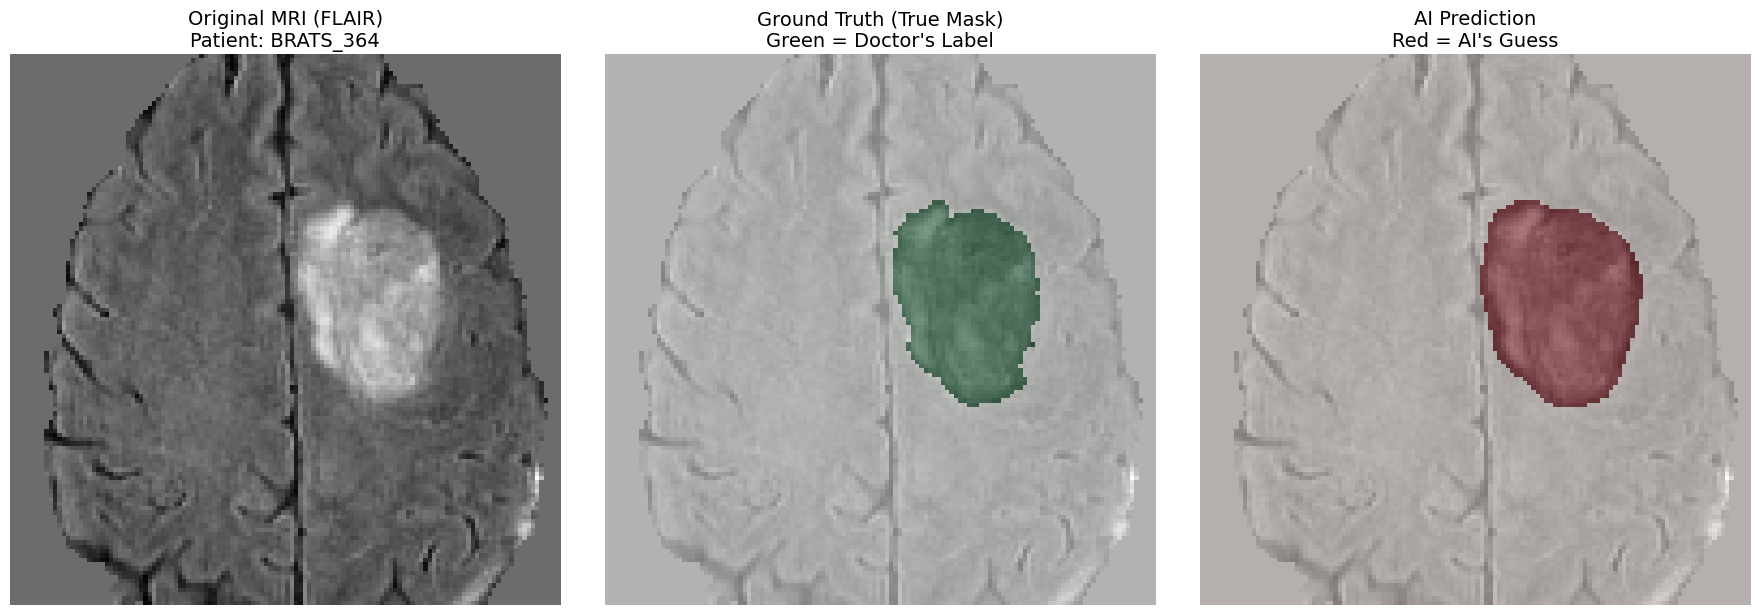

In [11]:
"""
=============================================================================
MILESTONE 5: INFERENCE & VISUALIZATION (THE FINAL EXAM)
=============================================================================
WHAT WE ARE DOING:
1. We load the absolute smartest version of your AI from the hard drive.
2. We give it a patient from the TEST set (data it has never seen before).
3. We convert its mathematical probabilities into a physical picture and 
   compare it side-by-side with the real doctor's mask.

WHY WE DO IT THIS WAY:
Loss numbers are great for computers, but humans need visual proof. 
For your thesis and PhD applications, generating these side-by-side 
comparisons proves your architecture actually works in the real world.
=============================================================================
"""
import matplotlib.pyplot as plt
import torch

print("Loading the best AI model for the final exam...")

# 1. Load the best saved weights into our model
model.load_state_dict(torch.load('/kaggle/working/best_unet_model.pth'))
model.eval() # Strictly disable learning during testing

# 2. Grab the very first patient from the completely unseen Test Set
test_iterator = iter(test_loader)
batch = next(test_iterator)

# 3. We use the Center Cropper to fit the GPU memory
images, labels = extract_center_patch(batch['image'], batch['label'])
images = images.to(device)
labels = labels.to(device)

# 4. Ask the AI to predict the tumor
with torch.no_grad():
    logits = model(images)
    
    # Convert raw math (-inf to +inf) into percentages (0.0 to 1.0)
    probabilities = torch.sigmoid(logits)
    
    # Threshold: Anything over 50% confident becomes a solid tumor pixel (1.0)
    predictions = (probabilities > 0.5).float()

# 5. Bring the tensors back to the CPU so matplotlib can draw them
# .squeeze(0) removes the "Batch" dimension so we just have (Channels, H, W, D)
images_cpu = images.squeeze(0).cpu().numpy()
labels_cpu = labels.squeeze(0).cpu().numpy()
preds_cpu = predictions.squeeze(0).cpu().numpy()
patient_id = batch['patient_id'][0]

# 6. Find a horizontal slice that actually has some tumor in the true mask
# Channel 0 is the "Whole Tumor" mask. We sum across Height and Width to find the Depth.
z_sums = labels_cpu[0].sum(axis=(0, 1)) 
best_z = z_sums.argmax() # Find the slice with the highest number of tumor pixels

print(f"Visualizing Patient: {patient_id} at Slice Depth: {best_z}\n")

# 7. Draw the side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: Original MRI (FLAIR channel is index 0)
axes[0].imshow(images_cpu[0, :, :, best_z].T, cmap='gray', origin='lower')
axes[0].set_title(f"Original MRI (FLAIR)\nPatient: {patient_id}", fontsize=14)
axes[0].axis('off')

# Panel 2: Ground Truth (Real Doctor's Mask - Whole Tumor)
axes[1].imshow(images_cpu[0, :, :, best_z].T, cmap='gray', origin='lower')
axes[1].imshow(labels_cpu[0, :, :, best_z].T, cmap='Greens', alpha=0.5, origin='lower')
axes[1].set_title("Ground Truth (True Mask)\nGreen = Doctor's Label", fontsize=14)
axes[1].axis('off')

# Panel 3: AI Prediction (Whole Tumor)
axes[2].imshow(images_cpu[0, :, :, best_z].T, cmap='gray', origin='lower')
axes[2].imshow(preds_cpu[0, :, :, best_z].T, cmap='Reds', alpha=0.5, origin='lower')
axes[2].set_title("AI Prediction\nRed = AI's Guess", fontsize=14)
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
"""
=============================================================================
MILESTONE 5B: QUANTITATIVE TEST-SET EVALUATION (PER-REGION DICE)
=============================================================================
Runs the best model on every TEST patient (full volume, padded to a multiple of 8)
and reports the Dice score for Whole Tumor (WT), Tumor Core (TC) and Enhancing
Tumor (ET), the standard BraTS / Decathlon regions. Results are saved to CSV.
=============================================================================
"""
import torch.nn.functional as F

def dice_score(pred, target, eps=1e-6):
    """Binary Dice. If both masks are empty the case is a perfect match (1.0)."""
    p, t = pred.flatten(), target.flatten()
    if p.sum() == 0 and t.sum() == 0:
        return 1.0
    return float((2 * (p * t).sum() + eps) / (p.sum() + t.sum() + eps))

model.load_state_dict(torch.load(save_path, map_location=device))
model.eval()

REGIONS = ["WT", "TC", "ET"]
rows = []
with torch.no_grad():
    for batch in test_loader:
        img, lbl = batch["image"].to(device), batch["label"].to(device)
        H, W, D = img.shape[2:]
        pads = [(8 - n % 8) % 8 for n in (H, W, D)]
        x = F.pad(img, (0, pads[2], 0, pads[1], 0, pads[0]))
        pred = (torch.sigmoid(model(x))[:, :, :H, :W, :D] > 0.5).float()
        row = {"patient_id": batch["patient_id"][0]}
        for k, r in enumerate(REGIONS):
            row[r] = dice_score(pred[0, k], lbl[0, k])
        rows.append(row)

results = pd.DataFrame(rows)
results.to_csv("/kaggle/working/test_dice_per_patient.csv", index=False)
print(f"Test patients evaluated: {len(results)}")
for r in REGIONS:
    print(f"  {r} Dice: {results[r].mean():.4f} +/- {results[r].std():.4f}  (median {results[r].median():.4f})")
print(f"  Mean Dice over regions: {results[REGIONS].values.mean():.4f}")
